# 06. Re-ranking: правила поверх ленты CatBoost

Стадия: re-ranking. Ranking (`05_ranking.ipynb`) учится одному – поставить наверх то, что человек, скорее всего, досмотрит. Лента – не просто «10 самых вероятных»: у неё есть продуктовые требования, которых ранжер не знает:

- не показывать продолжение тому, кто не досмотрел приквел;
- не забивать ленту частями одной франшизы;
- показывать не только хиты: критерий итогового списка из `02_baselines.ipynb` требует `coverage@10` хотя бы в 10 раз больше, чем у популярности, при `ndcg@10` не ниже 90% от неё.

Re-ranking берёт 100 кандидатов с баллами CatBoost и собирает из них ленту из 10 по правилам. Главный компромисс: офлайн-`ndcg@10` может упасть, а то, ради чего правила вводятся (ленту не забивает одна франшиза), офлайн-метрика не видит – у нас нет показов и кликов, только «досмотрел или нет».

Код: правила – `packages/serving/src/serving/rerank.py` (их будет применять сервис выдачи), оценка – `packages/training/src/training/reranking/evaluate.py`, данные каталога (приквелы, франшизы) – `packages/core/src/core/catalog/franchise.py`.

## Лента CatBoost как есть

Обучаем CatBoost на всех признаках (как в `05_ranking.ipynb`), ставим баллы val-кандидатам и берём у каждого пользователя 10 лучших. Пороги критерия считаем от популярности на тех же val-пользователях.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from core import config
from core.settings import RERANK
from training.ranking import model as rk
from training.reranking import evaluate as ev

# признаки кандидатов, данные для правил и баллы CatBoost на val
data, columns = rk.prepare()
context = ev.load_context()
scored = ev.score_val(data, columns)

# пороги критерия итогового списка: 90% точности и 10× покрытия популярности
criterion = ev.criterion_thresholds(context)
ndcg_min = criterion.ndcg_min
coverage_min = criterion.coverage_min
print(f"критерий: ndcg@10 >= {ndcg_min:.3f}, coverage@10 >= {coverage_min:.3f}")

D:\Projects\Python\ml\shikimori-rec-sys\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


критерий: ndcg@10 >= 0.206, coverage@10 >= 0.119


In [2]:
# лента CatBoost без правил: точность и свойства выдачи
plain_feeds = ev.build_feeds(scored, context, require_prequel=False)
plain_per_user, plain_summary = ev.feed_metrics(plain_feeds, context)
pd.Series({"ndcg@10": plain_per_user["ndcg@10"].mean(), **plain_summary.as_row()}).round(4)

ndcg@10              0.5898
coverage@10          0.0813
franchise_repeats    0.0925
max_franchise        1.7803
no_prequel           0.0439
dtype: float64

Как читать: `franchise_repeats` – доля мест ленты, занятых повтором франшизы (вторая, третья и т. д. часть одной франшизы); `max_franchise` – сколько в среднем аниме самой частой франшизы в ленте; `no_prequel` – доля мест с продолжением, приквел которого пользователь не досмотрел.

Лента пользователя, у которого одна франшиза заняла больше всего мест:

In [3]:
names = pd.read_csv(config.SOURCE / "anime.csv", usecols=["anime_id", "name"]).set_index("anime_id")["name"]


def most_repeated_user(feeds: dict) -> int:
    """Пользователь, у которого одна франшиза заняла больше всего мест ленты."""
    counts = {u: context.franchise_of.reindex(feed).value_counts().max() for u, feed in feeds.items()}
    return max(counts, key=counts.get)


def show_feed(feed: np.ndarray, user_id: int) -> pd.DataFrame:
    """Лента с названиями, франшизами и отметкой, угадано ли аниме."""
    hidden = context.cases[user_id][1]
    return pd.DataFrame({
        "name": names.reindex(feed).values,
        "франшиза": context.franchise_of.reindex(feed).values,
        "угадано": [a in hidden for a in feed],
    })


example_user = most_repeated_user(plain_feeds)
show_feed(plain_feeds[example_user], example_user)

,name,франшиза,угадано
0,Naruto: Shippuuden Movie 5 - Blood Prison,naruto,True
1,Naruto Movie 2: Dai Gekitotsu! Maboroshi no Ch...,naruto,True
2,Kimi no Na wa.,your_name,True
3,Naruto: The Cross Roads,naruto,True
4,Naruto: Akaki Yotsuba no Clover wo Sagase,naruto,True
5,Sen to Chihiro no Kamikakushi,anime_199,True
6,Naruto: Shippuuden Movie 1,naruto,True
7,"Tokyo Ghoul: ""Jack""",tokyo_ghoul,True
8,Sword Art Online: Alicization,sword_art_online,True
9,Naruto: Dai Katsugeki!! Yuki Hime Ninpouchou D...,naruto,True


## Правила

`serving.rerank.rerank` собирает ленту в три шага:

1. **Сначала приквел.** Продолжение показываем, только если пользователь досмотрел хотя бы один его прямой приквел (связи `sequel`/`prequel` из `anime_relations`, приквелы только из каталога).
2. **Штраф за популярность.** Итоговый балл – балл CatBoost минус `popularity_weight` × популярность; оба приведены к среднему 0 и разбросу 1 внутри 100 кандидатов пользователя, чтобы сила штрафа значила одно и то же для всех.
3. **Лимит франшизы.** Идём по убыванию итогового балла и пропускаем аниме сверх `max_per_franchise` из одной франшизы, пока лента не наберёт 10. На место пропущенных поднимаются следующие кандидаты.

Сетка: лимит франшизы × сила штрафа. Первая строка – CatBoost без правил, вторая – только «сначала приквел»; в остальных строках правило о приквелах включено. `diff` – парная разница `ndcg@10` с лентой CatBoost и её 95% интервал.

In [4]:
weights = (0.0, 0.25, 0.5, 0.6, 0.65, 0.7, 0.75, 1.0)
grid = ev.sweep(scored, context, criterion, limits=(None, 3, 2, 1), weights=weights)
grid.round(4)

,сначала приквел,лимит франшизы,штраф за популярность,ndcg@10,diff,diff_low,diff_high,coverage@10,franchise_repeats,max_franchise,no_prequel,критерий
0,нет,нет,0.00,0.5898,0.0000,0.0000,0.0000,0.0813,0.0925,1.7803,0.0439,False
1,да,нет,0.00,0.5922,0.0024,-0.0024,0.0080,0.0826,0.0763,1.6590,0.0000,False
2,да,нет,0.25,0.5839,-0.0059,-0.0152,0.0031,0.0971,0.0994,1.8439,0.0000,False
3,да,нет,0.50,0.5545,-0.0353,-0.0512,-0.0195,0.1141,0.1277,2.0636,0.0000,False
4,да,нет,0.60,0.5369,-0.0529,-0.0700,-0.0358,0.1207,0.1393,2.1445,0.0000,True
5,да,нет,0.65,0.5263,-0.0635,-0.0818,-0.0450,0.1236,0.1434,2.1676,0.0000,True
6,да,нет,0.70,0.5177,-0.0721,-0.0915,-0.0529,0.1262,0.1474,2.1965,0.0000,True
7,да,нет,0.75,0.5091,-0.0807,-0.1006,-0.0607,0.1302,0.1509,2.2081,0.0000,True
8,да,нет,1.00,0.4460,-0.1437,-0.1692,-0.1189,0.1446,0.1734,2.3988,0.0000,True
9,да,3,0.00,0.5905,0.0007,-0.0048,0.0066,0.0826,0.0659,1.5318,0.0000,False


Точность против покрытия: каждая точка – одна настройка, цвет – лимит франшизы, подпись – сила штрафа. Критерий выполнен правее вертикального пунктира (покрытие) и выше горизонтального (точность).

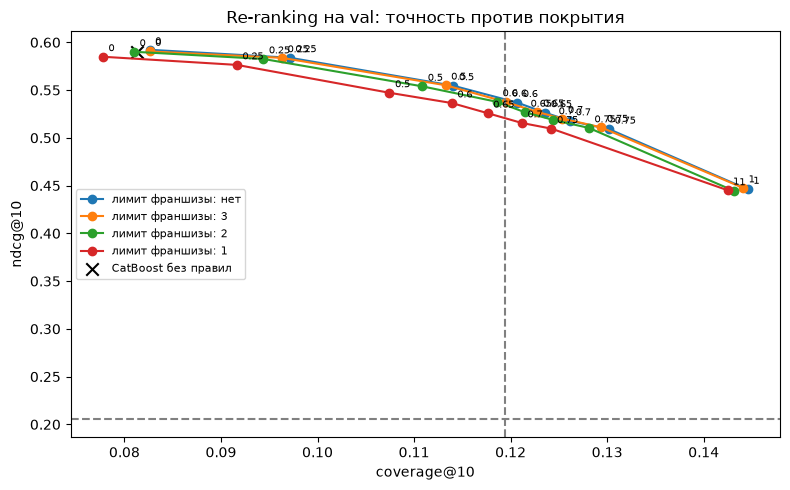

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
for limit, rows in grid[grid["сначала приквел"] == "да"].groupby("лимит франшизы", sort=False):
    ax.plot(rows["coverage@10"], rows["ndcg@10"], marker="o", label=f"лимит франшизы: {limit}")
    for _, row in rows.iterrows():
        ax.annotate(f"{row['штраф за популярность']:g}", (row["coverage@10"], row["ndcg@10"]), textcoords="offset points", xytext=(4, 4), fontsize=7)
plain_row = grid.iloc[0]
ax.scatter(plain_row["coverage@10"], plain_row["ndcg@10"], color="black", marker="x", s=80, label="CatBoost без правил")
ax.axvline(coverage_min, linestyle="--", color="gray")
ax.axhline(ndcg_min, linestyle="--", color="gray")
ax.set_xlabel("coverage@10")
ax.set_ylabel("ndcg@10")
ax.set_title("Re-ranking на val: точность против покрытия")
ax.legend(fontsize=8)
plt.tight_layout()

## Выбранная настройка

Берём наименьший штраф за популярность, при котором с лимитом в одно аниме на франшизу выполняется критерий. Эта настройка записана в `core/settings.py` (`RERANK`) и сохраняется вместе с артефактами выдачи (`models/rerank_v0/settings.json`). Ниже – её метрики рядом с лентой CatBoost и лента того же пользователя после правил.

In [6]:
# принятая настройка хранится в коде выдачи, здесь только читаем её
LIMIT = RERANK.max_per_franchise
WEIGHT = RERANK.popularity_weight

chosen_feeds = ev.build_feeds(scored, context, max_per_franchise=LIMIT, popularity_weight=WEIGHT)
chosen_per_user, chosen_summary = ev.feed_metrics(chosen_feeds, context)
pd.DataFrame({
    "CatBoost": {"ndcg@10": plain_per_user["ndcg@10"].mean(), "hit_rate@10": plain_per_user["hit_rate@10"].mean(), **plain_summary.as_row()},
    "re-ranking": {"ndcg@10": chosen_per_user["ndcg@10"].mean(), "hit_rate@10": chosen_per_user["hit_rate@10"].mean(), **chosen_summary.as_row()},
}).round(4)

,CatBoost,re-ranking
ndcg@10,0.5898,0.5156
hit_rate@10,0.9249,0.9249
coverage@10,0.0813,0.1212
franchise_repeats,0.0925,0.0000
max_franchise,1.7803,1.0000
no_prequel,0.0439,0.0000


In [7]:
show_feed(chosen_feeds[example_user], example_user)

,name,франшиза,угадано
0,Naruto: Shippuuden Movie 5 - Blood Prison,naruto,True
1,Overlord: Ple Ple Pleiades - Nazarick Saidai n...,overlord,False
2,Quanzhi Gaoshou 2,quanzhi_gaoshou,True
3,"Tokyo Ghoul: ""Jack""",tokyo_ghoul,True
4,Kuroko no Basket NG-shuu,kuroko_no_basket,True
5,Fullmetal Alchemist: Premium Collection,fullmetal_alchemist,True
6,Ao no Exorcist Movie,ao_no_exorcist,True
7,Hunter x Hunter Movie 1: Phantom Rouge,hunter_x_hunter,False
8,Tensei shitara Slime Datta Ken OVA,tensei_shitara_slime_datta_ken,False
9,Ansatsu Kyoushitsu: 365-nichi no Jikan,ansatsu_kyoushitsu,True


Что именно поднимает штраф за популярность: доли типов аниме в лентах и среди спрятанных ответов (то, что люди на самом деле досматривают).

In [8]:
kind = pd.read_csv(config.SOURCE / "anime.csv", usecols=["anime_id", "kind"]).set_index("anime_id")["kind"]
hidden_ids = [a for _, (_, hidden) in context.cases.items() for a in hidden]
shown = {"спрятанные ответы": hidden_ids,
         "CatBoost": np.concatenate(list(plain_feeds.values())),
         "re-ranking": np.concatenate(list(chosen_feeds.values()))}
pd.DataFrame({name: pd.Series(ids).map(kind).value_counts(normalize=True) for name, ids in shown.items()}).fillna(0).round(3)

,спрятанные ответы,CatBoost,re-ranking
movie,0.151,0.237,0.239
ona,0.051,0.021,0.036
ova,0.075,0.034,0.045
special,0.056,0.014,0.035
tv,0.652,0.684,0.631
tv_special,0.016,0.010,0.015


Вывод:

- **Лента CatBoost нарушает продуктовые правила.** В 4,4% мест – продолжения без досмотренного приквела, и угадываются они редко; 9% мест – повторы одной франшизы, у пользователя из примера 6 из 10 – фильмы «Наруто» (все угаданы: офлайн-метрика такую ленту поощряет). `coverage@10` 0,081 при пороге 0,119 – критерий итогового списка не выполнен.
- **«Сначала приквел» бесплатен:** `ndcg@10` +0,002 [−0,002; 0,008], продолжений без приквела в ленте не остаётся.
- **Лимит франшизы почти бесплатен:** с одним аниме на франшизу `ndcg@10` −0,005 [−0,016; 0,006], разница не значима. На место убранных частей поднимаются следующие кандидаты CatBoost, и они тоже часто правильные.
- **Покрытие стоит точности.** Критерий выполняется только при штрафе за популярность не меньше 0,70 (лимит 1) или 0,65 (лимит 2); при штрафе 0,5 покрытие 0,107–0,114, чуть ниже порога.
- **Выбранная настройка – «сначала приквел» + одно аниме на франшизу + штраф 0,7:** `ndcg@10` 0,516 (−0,074 [−0,095; −0,055] к ленте CatBoost, но выше порядка iALS без ranking, 0,484, и в 2,5 раза выше порога 0,206), `coverage@10` 0,121 – критерий выполнен; повторов франшиз и продолжений без приквела нет. `hit_rate@10` не меняется (0,925): хотя бы одно попадание остаётся почти у всех. У пользователя из примера угадано 7 из 10, но из 9 разных франшиз.
- **Штраф поднимает не случайные редкости:** в ленте становится больше OVA, спецвыпусков и ONA, то есть ближе к тому, что люди досматривают на самом деле (типы спрятанных ответов). CatBoost их недопоказывал.
- **Ограничения.** Ради чего вводится лимит франшизы – чтобы лента не надоедала, – офлайн-метрика не видит: у нас нет показов и кликов. Порог покрытия («в 10 раз больше популярности») задан нами, а штраф подобран на тех же 173 val-пользователях. Проверять настройку стоит симуляцией обратной связи или A/B-тестом.
- **Следующий шаг:** экспорт ranking и правил в сервис выдачи и симуляция A/B против популярности.